# Problema 4 - Classificação de Risco de Crédito com Árvore de Decisão

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FredGregorio/Disciplina-sistemas-inteligentes-2026.2/blob/main/Primeira%20Unidade/Projetos/04-arvore-decisao-german-credit/src/problema4.ipynb)

## 1. Importando as bibliotecas e carregando os dados

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report
)

plt.rcParams['figure.figsize'] = (8, 4)

In [2]:
# Se o arquivo existir na pasta do projeto, estamos rodando no PC.
# Se não existir (ex.: Google Colab), baixamos o mesmo arquivo do GitHub.
if os.path.exists("../data/credit_g.csv"):
    caminho_dados = "../data/credit_g.csv"
    pasta_resultados = "../resultados"
else:
    caminho_dados = "https://raw.githubusercontent.com/FredGregorio/Disciplina-sistemas-inteligentes-2026.2/main/Primeira%20Unidade/Projetos/04-arvore-decisao-german-credit/data/credit_g.csv"
    pasta_resultados = "resultados"

os.makedirs(pasta_resultados, exist_ok=True)   # pasta onde salvamos os gráficos

df = pd.read_csv(caminho_dados)
df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [3]:
print(f"Quantidade de solicitações = {df.shape[0]}")
print(f"Quantidade de atributos    = {df.shape[1] - 1}  (+ a coluna 'class')")
print(f"Valores ausentes           = {df.isna().sum().sum()}")

Quantidade de solicitações = 1000
Quantidade de atributos    = 20  (+ a coluna 'class')
Valores ausentes           = 0


## 2. Tarefa 1 - Preparação dos dados

### 2.1 Atributos numéricos e categóricos

In [4]:
X = df.drop(columns=["class"])
y = df["class"]

numericos = X.select_dtypes(include="number").columns.tolist()
categoricos = X.select_dtypes(exclude="number").columns.tolist()

print(f"Numéricos ({len(numericos)}):", numericos)
print()
print(f"Categóricos ({len(categoricos)}):", categoricos)

Numéricos (7): ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Categóricos (13): ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']


In [5]:
print(X["checking_status"].value_counts())

checking_status
no checking    394
<0             274
0<=X<200       269
>=200           63
Name: count, dtype: int64


### 2.2 Codificação das variáveis categóricas (one-hot encoding)

In [6]:
X = pd.get_dummies(X, columns=categoricos, dtype=int)

print(f"Atributos após o one-hot: {X.shape[1]}")
print(list(X.columns[:12]), "...")

Atributos após o one-hot: 61
['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents', 'checking_status_0<=X<200', 'checking_status_<0', 'checking_status_>=200', 'checking_status_no checking', 'credit_history_all paid'] ...


### 2.3 Balanceamento das classes

In [7]:
print(y.value_counts())
print()
print((y.value_counts(normalize=True) * 100).round(1).astype(str) + " %")

class
good    700
bad     300
Name: count, dtype: int64

class
good    70.0 %
bad     30.0 %
Name: proportion, dtype: str


## 3. Tarefa 2 - Por que não é preciso normalizar?

## 4. Tarefa 3 - Divisão treino/teste (estratificada)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]} | Teste: {X_test.shape[0]}\n")
print(pd.DataFrame({
    "treino (%)": y_train.value_counts(normalize=True) * 100,
    "teste (%)":  y_test.value_counts(normalize=True) * 100,
}).round(1))

Treino: 800 | Teste: 200

       treino (%)  teste (%)
class                       
good         70.0       70.0
bad          30.0       30.0


## 5. Tarefa 4 - Profundidade máxima e controle de complexidade

In [9]:
profundidades = [2, 3, 5, 7, 10, None]       # None = sem limite
nomes = [str(p) if p is not None else "sem limite" for p in profundidades]

def avaliar_profundidades(criterio):
    resultados = []
    for p in profundidades:
        arvore = DecisionTreeClassifier(criterion=criterio, max_depth=p, random_state=42)
        cv = cross_validate(arvore, X_train, y_train, cv=5, return_train_score=True)
        resultados.append({
            "profundidade": str(p) if p is not None else "sem limite",
            "acc_treino": cv["train_score"].mean(),
            "acc_validacao": cv["test_score"].mean(),
            "desvio_validacao": cv["test_score"].std(),
        })
    return pd.DataFrame(resultados)

res_gini = avaliar_profundidades("gini")
print("Critério: GINI")
print(res_gini.round(4).to_string(index=False))

Critério: GINI
profundidade  acc_treino  acc_validacao  desvio_validacao
           2      0.7225         0.7062            0.0079
           3      0.7447         0.6925            0.0150
           5      0.8056         0.6925            0.0199
           7      0.8634         0.6912            0.0361
          10      0.9381         0.6900            0.0276
  sem limite      1.0000         0.6812            0.0424


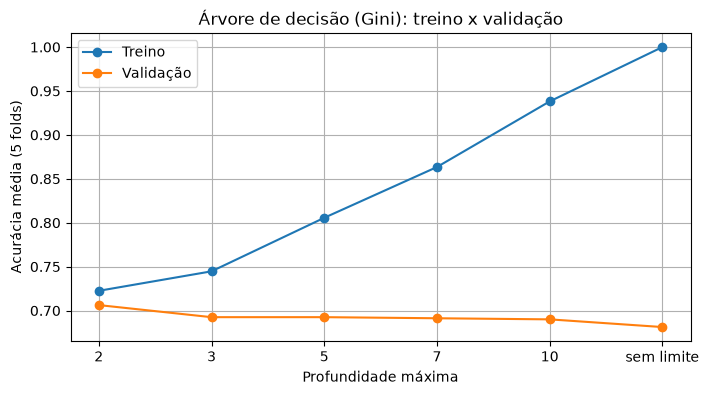

In [10]:
plt.plot(nomes, res_gini["acc_treino"], marker='o', label="Treino")
plt.plot(nomes, res_gini["acc_validacao"], marker='o', label="Validação")
plt.xlabel("Profundidade máxima")
plt.ylabel("Acurácia média (5 folds)")
plt.title("Árvore de decisão (Gini): treino x validação")
plt.legend()
plt.grid()
plt.savefig(f"{pasta_resultados}/profundidade_gini.png", dpi=150)
plt.show()

In [11]:
melhor_gini = res_gini.loc[res_gini["acc_validacao"].idxmax()]
print(f"Melhor profundidade (Gini): {melhor_gini['profundidade']} "
      f"-> validação = {melhor_gini['acc_validacao']:.4f}")

Melhor profundidade (Gini): 2 -> validação = 0.7063


### 5.1 Repetindo com o critério de entropia

In [12]:
res_entropia = avaliar_profundidades("entropy")
print("Critério: ENTROPIA")
print(res_entropia.round(4).to_string(index=False))

melhor_entropia = res_entropia.loc[res_entropia["acc_validacao"].idxmax()]
print(f"\nMelhor profundidade (entropia): {melhor_entropia['profundidade']} "
      f"-> validação = {melhor_entropia['acc_validacao']:.4f}")

Critério: ENTROPIA
profundidade  acc_treino  acc_validacao  desvio_validacao
           2      0.7128         0.7062            0.0079
           3      0.7322         0.7012            0.0187
           5      0.7934         0.7075            0.0207
           7      0.8428         0.6938            0.0172
          10      0.9175         0.6788            0.0156
  sem limite      1.0000         0.6800            0.0348

Melhor profundidade (entropia): 5 -> validação = 0.7075


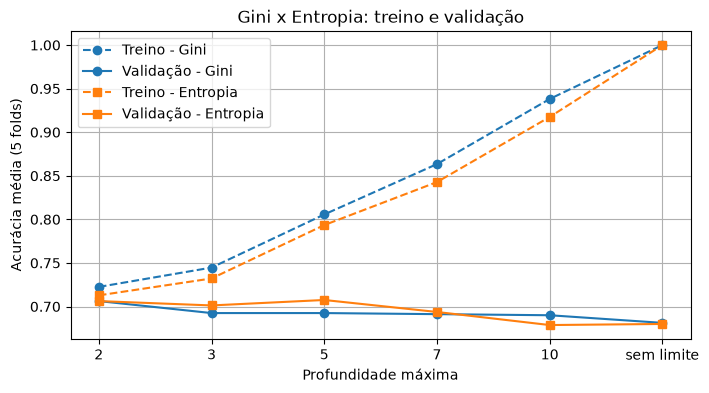

In [13]:
plt.plot(nomes, res_gini["acc_treino"], marker='o', linestyle='--', color="tab:blue", label="Treino - Gini")
plt.plot(nomes, res_gini["acc_validacao"], marker='o', color="tab:blue", label="Validação - Gini")
plt.plot(nomes, res_entropia["acc_treino"], marker='s', linestyle='--', color="tab:orange", label="Treino - Entropia")
plt.plot(nomes, res_entropia["acc_validacao"], marker='s', color="tab:orange", label="Validação - Entropia")
plt.xlabel("Profundidade máxima")
plt.ylabel("Acurácia média (5 folds)")
plt.title("Gini x Entropia: treino e validação")
plt.legend()
plt.grid()
plt.savefig(f"{pasta_resultados}/gini_vs_entropia.png", dpi=150)
plt.show()

In [14]:
arvore_gini2 = DecisionTreeClassifier(criterion="gini", max_depth=2, random_state=42)
arvore_gini2.fit(X_train, y_train)

print(export_text(arvore_gini2, feature_names=list(X.columns)))
print("Previsões no treino:", pd.Series(arvore_gini2.predict(X_train)).value_counts().to_dict())

|--- checking_status_no checking <= 0.50
|   |--- duration <= 11.50
|   |   |--- class: good
|   |--- duration >  11.50
|   |   |--- class: good
|--- checking_status_no checking >  0.50
|   |--- other_payment_plans_none <= 0.50
|   |   |--- class: good
|   |--- other_payment_plans_none >  0.50
|   |   |--- class: good

Previsões no treino: {'good': 800}


## 6. Tarefa 5 - Interpretação do modelo

In [15]:
# Escolha feita na Tarefa 4: entropia com profundidade 5
MELHOR_CRITERIO = 'entropy'
MELHOR_PROFUNDIDADE = 5

In [16]:
modelo = DecisionTreeClassifier(criterion=MELHOR_CRITERIO, max_depth=MELHOR_PROFUNDIDADE, random_state=42)
modelo.fit(X_train, y_train)

print(f"Árvore: critério = {MELHOR_CRITERIO}, profundidade máxima = {MELHOR_PROFUNDIDADE}")
print(f"Quantidade de folhas = {modelo.get_n_leaves()}")

Árvore: critério = entropy, profundidade máxima = 5
Quantidade de folhas = 25


### 6.1 Visualização gráfica da árvore

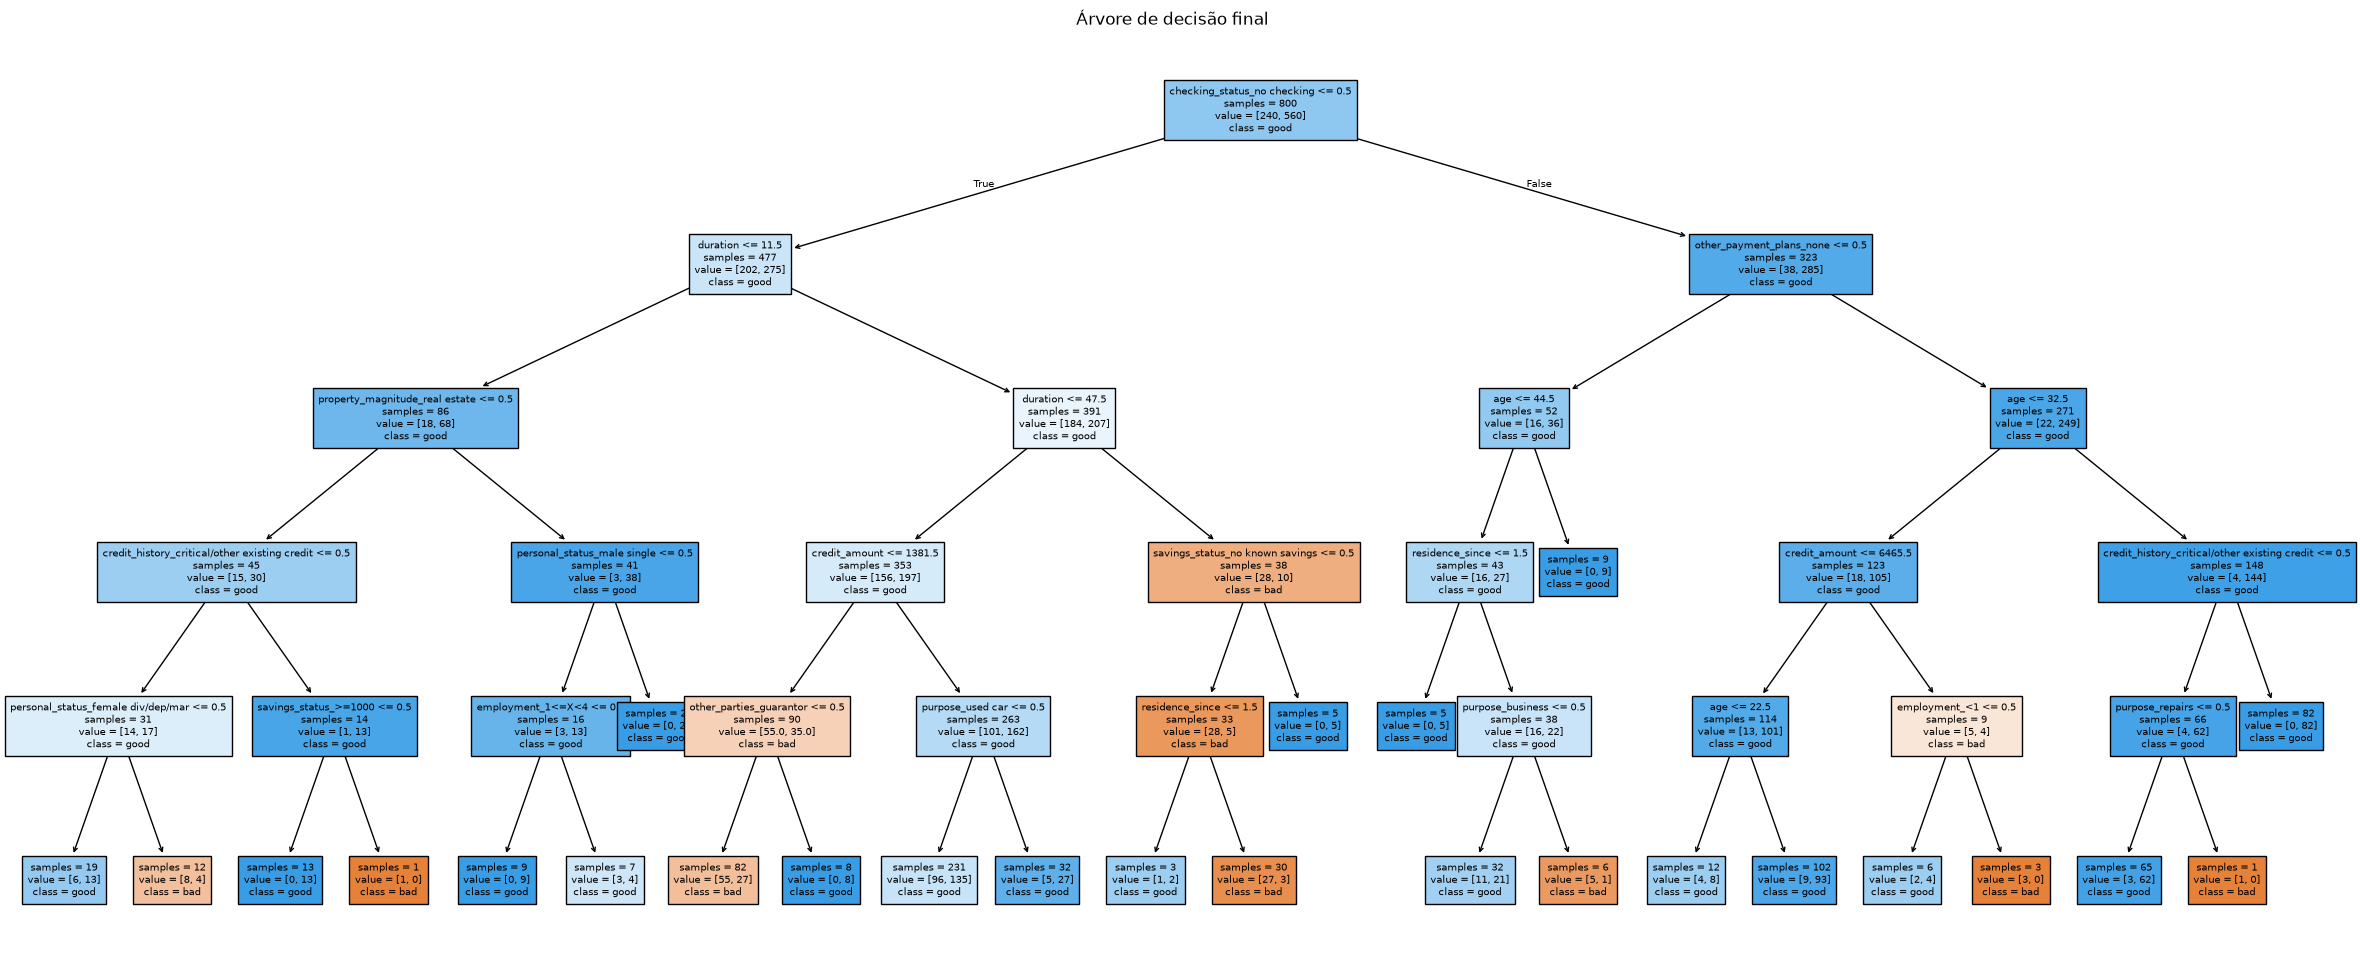

In [17]:
fig, ax = plt.subplots(figsize=(30, 12))
plot_tree(
    modelo,
    feature_names=list(X.columns),
    class_names=list(modelo.classes_),
    filled=True,
    impurity=False,
    proportion=False,
    fontsize=7,
    ax=ax,
)
plt.title("Árvore de decisão final")
plt.savefig(f"{pasta_resultados}/arvore.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
print(export_text(modelo, feature_names=list(X.columns)))

|--- checking_status_no checking <= 0.50
|   |--- duration <= 11.50
|   |   |--- property_magnitude_real estate <= 0.50
|   |   |   |--- credit_history_critical/other existing credit <= 0.50
|   |   |   |   |--- personal_status_female div/dep/mar <= 0.50
|   |   |   |   |   |--- class: good
|   |   |   |   |--- personal_status_female div/dep/mar >  0.50
|   |   |   |   |   |--- class: bad
|   |   |   |--- credit_history_critical/other existing credit >  0.50
|   |   |   |   |--- savings_status_>=1000 <= 0.50
|   |   |   |   |   |--- class: good
|   |   |   |   |--- savings_status_>=1000 >  0.50
|   |   |   |   |   |--- class: bad
|   |   |--- property_magnitude_real estate >  0.50
|   |   |   |--- personal_status_male single <= 0.50
|   |   |   |   |--- employment_1<=X<4 <= 0.50
|   |   |   |   |   |--- class: good
|   |   |   |   |--- employment_1<=X<4 >  0.50
|   |   |   |   |   |--- class: good
|   |   |   |--- personal_status_male single >  0.50
|   |   |   |   |--- class: good
|  

### 6.2 Importância dos atributos

checking_status_no checking                      0.3055
duration                                         0.1094
age                                              0.0839
credit_amount                                    0.0757
other_payment_plans_none                         0.0561
other_parties_guarantor                          0.0536
savings_status_no known savings                  0.0515
credit_history_critical/other existing credit    0.0458
residence_since                                  0.0320
property_magnitude_real estate                   0.0311
purpose_used car                                 0.0293
savings_status_>=1000                            0.0236
personal_status_male single                      0.0197
employment_1<=X<4                                0.0192
purpose_repairs                                  0.0192
purpose_business                                 0.0168
employment_<1                                    0.0155
personal_status_female div/dep/mar              

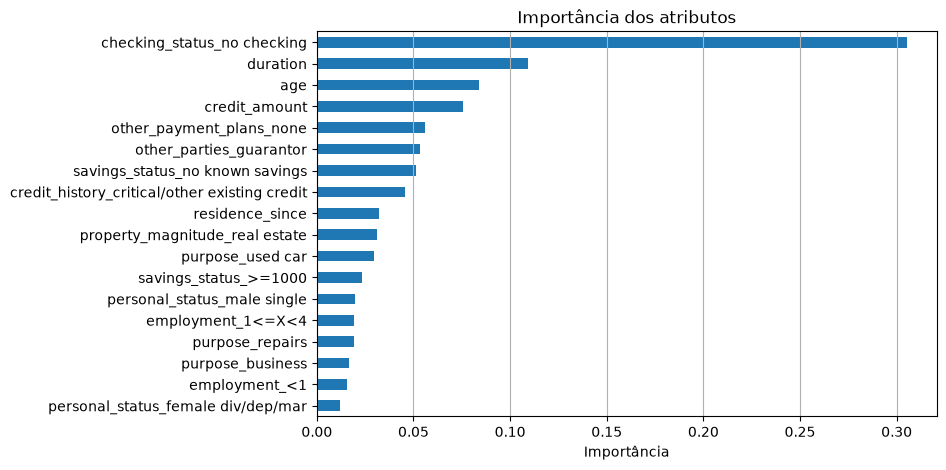

In [19]:
importancia = pd.Series(modelo.feature_importances_, index=X.columns)
importancia = importancia[importancia > 0].sort_values(ascending=False)
print(importancia.round(4))

importancia.sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("Importância")
plt.title("Importância dos atributos")
plt.grid(axis="x")
plt.savefig(f"{pasta_resultados}/importancia_atributos.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Caminho até a folha com mais maus pagadores

In [20]:
folha_de_cada_cliente = modelo.apply(X_train)
contagem = pd.crosstab(folha_de_cada_cliente, y_train)    # linhas = folhas, colunas = bad/good
print(contagem.sort_values("bad", ascending=False).head())

folha_alvo = contagem["bad"].idxmax()
print(f"\nFolha com mais maus pagadores: nó {folha_alvo} "
      f"({contagem.loc[folha_alvo, 'bad']} bad x {contagem.loc[folha_alvo, 'good']} good)")

class  bad  good
row_0           
21      96   135
18      55    27
26      27     3
33      11    21
40       9    93

Folha com mais maus pagadores: nó 21 (96 bad x 135 good)


In [21]:
arv = modelo.tree_

# Para cada nó, guardamos quem é o "pai" e se viemos pelo lado <= ou >
pai = {}
for no in range(arv.node_count):
    if arv.children_left[no] != -1:                  # -1 significa que é folha
        pai[arv.children_left[no]] = (no, "<=")
        pai[arv.children_right[no]] = (no, ">")

# Subimos da folha até a raiz
caminho = []
no = folha_alvo
while no in pai:
    no_pai, lado = pai[no]
    atributo = X.columns[arv.feature[no_pai]]
    caminho.append(f"{atributo} {lado} {arv.threshold[no_pai]:.2f}")
    no = no_pai
caminho.reverse()                                    # agora da raiz até a folha

for i, regra in enumerate(caminho, 1):
    print(f"{i}. {regra}")

1. checking_status_no checking <= 0.50
2. duration > 11.50
3. duration <= 47.50
4. credit_amount > 1381.50
5. purpose_used car <= 0.50


## 7. Tarefa 6 - Avaliação no conjunto de teste

Acurácia no teste: 0.7000

            prev: good  prev: bad
real: good         127         13
real: bad           47         13


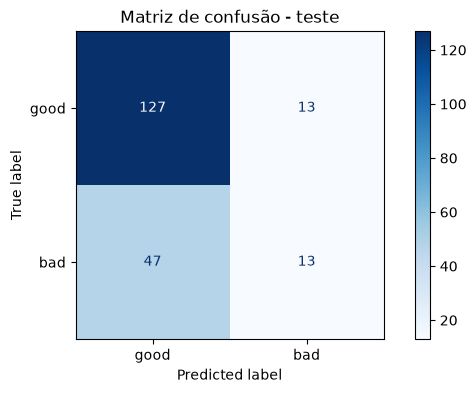

In [22]:
y_pred = modelo.predict(X_test)
classes = ["good", "bad"]

print(f"Acurácia no teste: {accuracy_score(y_test, y_pred):.4f}\n")

cm = confusion_matrix(y_test, y_pred, labels=classes)
print(pd.DataFrame(cm, index=[f"real: {c}" for c in classes], columns=[f"prev: {c}" for c in classes]))

ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap="Blues")
plt.title("Matriz de confusão - teste")
plt.savefig(f"{pasta_resultados}/matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
print(classification_report(y_test, y_pred, labels=classes, digits=4))

              precision    recall  f1-score   support

        good     0.7299    0.9071    0.8089       140
         bad     0.5000    0.2167    0.3023        60

    accuracy                         0.7000       200
   macro avg     0.6149    0.5619    0.5556       200
weighted avg     0.6609    0.7000    0.6569       200



### 7.1 Ajuste para reduzir o erro mais grave: `class_weight="balanced"`

In [24]:
modelo_bal = DecisionTreeClassifier(criterion=MELHOR_CRITERIO, max_depth=MELHOR_PROFUNDIDADE,
                                    class_weight="balanced", random_state=42)
modelo_bal.fit(X_train, y_train)
y_pred_bal = modelo_bal.predict(X_test)

print(f"Acurácia no teste: {accuracy_score(y_test, y_pred_bal):.4f}\n")
print(pd.DataFrame(confusion_matrix(y_test, y_pred_bal, labels=classes),
                   index=[f"real: {c}" for c in classes], columns=[f"prev: {c}" for c in classes]))
print()
print(classification_report(y_test, y_pred_bal, labels=classes, digits=4))

Acurácia no teste: 0.6150

            prev: good  prev: bad
real: good          72         68
real: bad            9         51

              precision    recall  f1-score   support

        good     0.8889    0.5143    0.6516       140
         bad     0.4286    0.8500    0.5698        60

    accuracy                         0.6150       200
   macro avg     0.6587    0.6821    0.6107       200
weighted avg     0.7508    0.6150    0.6271       200

